== Overall funnel ==
      stage_name  stage_session_count  drop_off  step_cvr
   Session Start               352263         0     1.000
    Product View                74736    277527     0.212
     Add to Cart                14891     59845     0.199
  Begin Checkout                 5324      9567     0.358
Add Payment Info                 3782      1542     0.710
        Purchase                 2529      1253     0.669

== Step conversion by device ==
device_category   desktop  mobile  tablet
stage_name                               
Session Start       1.000   1.000   1.000
Product View        0.213   0.211   0.210
Add to Cart         0.198   0.201   0.192
Begin Checkout      0.355   0.361   0.354
Add Payment Info    0.705   0.715   0.768
Purchase            0.665   0.675   0.640


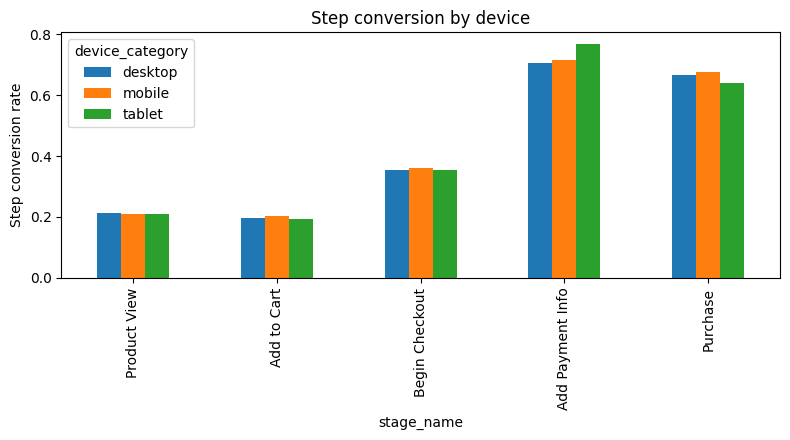


== Takeaway ==
- The biggest single drop-off is at 'Product View': 277,527 sessions lost (step conversion 21.2%).
- The step where devices differ the most is 'Add Payment Info': tablet converts at 76.8% vs desktop at 70.5% (a 6.3% gap).
- This is descriptive, not causal: it points to where to look, not why it happens.


In [7]:
"""
GA4 funnel: where do we lose the most users, and does it differ by device?

Input:  the weekly funnel table from the BigQuery SQL (one row per
        week x device x ... x funnel stage).
Output: two small tables (overall, by device) and one bar chart,
        saved to the 'out' folder, plus a plain-language takeaway printed below.
"""
import pandas as pd
import matplotlib.pyplot as plt

DATA_PATH = DATA_PATH = "/kaggle/input/datasets/maksymchobotarr/ga4-e-commerce-data-csv/ga4-e-commerce-data.csv"#"/kaggle/input/datasets/maksymchobotarr/ga4-e-commerce-data-csv"   # <- change to your file name
OUT_DIR = "out"

import os
os.makedirs(OUT_DIR, exist_ok=True)

df = pd.read_csv(DATA_PATH)

# --- overall funnel: how many sessions reach each stage, and the conversion step by step
overall = (df.groupby(["stage_order", "stage_name"], as_index=False)
             [["stage_session_count", "previous_stage_session_count"]].sum())
overall["step_cvr"] = overall["stage_session_count"] / overall["previous_stage_session_count"]
overall["drop_off"] = overall["previous_stage_session_count"] - overall["stage_session_count"]
print("== Overall funnel ==")
print(overall[["stage_name", "stage_session_count", "drop_off", "step_cvr"]].round(3).to_string(index=False))

# which step loses the most users in absolute terms (excluding stage 1, which has no "previous" step)
worst_overall = overall[overall["stage_order"] > 1].sort_values("drop_off", ascending=False).iloc[0]

# --- same breakdown, split by device
by_device = (df.groupby(["device_category", "stage_order", "stage_name"], as_index=False)
               [["stage_session_count", "previous_stage_session_count"]].sum())
by_device["step_cvr"] = by_device["stage_session_count"] / by_device["previous_stage_session_count"]
print("\n== Step conversion by device ==")
pivot = by_device.pivot(index="stage_name", columns="device_category", values="step_cvr")
pivot = pivot.reindex(overall.sort_values("stage_order")["stage_name"])  # keep funnel order
print(pivot.round(3).to_string())

# which step has the biggest gap between the best and worst device
pivot_no_first = pivot.iloc[1:]  # drop Session Start, it has no meaningful step_cvr
gap = (pivot_no_first.max(axis=1) - pivot_no_first.min(axis=1))
worst_step = gap.idxmax()
best_device, worst_device = pivot_no_first.loc[worst_step].idxmax(), pivot_no_first.loc[worst_step].idxmin()

overall.to_csv(f"{OUT_DIR}/funnel_overall.csv", index=False)
pivot.to_csv(f"{OUT_DIR}/funnel_by_device.csv")

# --- one simple chart: step conversion by device
pivot_no_first.plot(kind="bar", figsize=(8, 4.5))
plt.ylabel("Step conversion rate")
plt.title("Step conversion by device")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/funnel_by_device.png", dpi=150)
plt.show()

# --- plain-language takeaway, built from the numbers above
print("\n== Takeaway ==")
print(f"- The biggest single drop-off is at '{worst_overall['stage_name']}': "
      f"{int(worst_overall['drop_off']):,} sessions lost "
      f"(step conversion {worst_overall['step_cvr']:.1%}).")
print(f"- The step where devices differ the most is '{worst_step}': "
      f"{best_device} converts at {pivot_no_first.loc[worst_step, best_device]:.1%} vs "
      f"{worst_device} at {pivot_no_first.loc[worst_step, worst_device]:.1%} "
      f"(a {gap[worst_step]:.1%} gap).")
print("- This is descriptive, not causal: it points to where to look, not why it happens.")

In [8]:
# how many sessions back the "biggest device gap" step - small samples make the gap unreliable
n_check = by_device[by_device["stage_name"] == worst_step][["device_category", "previous_stage_session_count"]]
print(f"\nSessions behind the '{worst_step}' comparison above:")
print(n_check.to_string(index=False))


Sessions behind the 'Add Payment Info' comparison above:
device_category  previous_stage_session_count
        desktop                          3061
         mobile                          2151
         tablet                           112
